# 03. Batch 790 RCA — 1차 분석
Code 23 / Batch 790 | 2026-11-25

기존 789/799 산출물을 변경하지 않는다. 790은 기존 Train에 속하므로 최초 로그 시각보다 엄격히 이전에 완료된 동일 제품 배치만 기준으로 사용한다. 기존 97.5% 가상 하한은 사후 비교용이다. 새 기준은 과거 Q10과 100% 가상 상한으로 정의하며 승인 규격이 아니다. 수율 공개 지연 및 로그 시작/종료와 실제 생산 시각의 차이는 미확인이다. 공정 집계·품질·손실 변수는 종료 후 RCA에만 사용하며 인과관계를 확정하지 않는다. 폐기 카운터 해석 및 기존 Agent 스키마는 후속 검증 대상이다.

In [1]:
from pathlib import Path
from zipfile import ZipFile
import json, hashlib, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'data'/'Laboratory.csv').is_file()), None)
assert ROOT is not None, 'yield_experiment 폴더에서 실행하세요.'
DATA = ROOT/'data'
SPLIT = ROOT/'results'/'spec_all_products'/'all_product_batch_split.csv'
SPEC = ROOT/'results'/'spec_all_products_q10'/'all_product_specifications_q10.csv'
OUT = ROOT/'results'/'revision_20261125'/'03_batch790_rca'
OUT.mkdir(parents=True, exist_ok=True)
CODE, BATCH = 23, 790
KEY = ['code','batch']
MIN_REF = 20
paths = [DATA/'Laboratory.csv',DATA/'Process.csv',DATA/'Process.zip',SPLIT,SPEC]
hashes = {}
for p in paths:
    with p.open('rb') as f: hashes[str(p.relative_to(ROOT))] = hashlib.file_digest(f,'sha256').hexdigest()
print('Notebook 03 batch790 | phase 1', OUT)

Notebook 03 batch790 | phase 1 /Users/park-inki/Desktop/SKALA-yield-model/yield_experiment/results/revision_20261125/03_batch790_rca


## 1. 원본 결합 및 시간 기준 설정

In [2]:
lab=pd.read_csv(DATA/'Laboratory.csv',sep=';')
proc=pd.read_csv(DATA/'Process.csv',sep=';')
split=pd.read_csv(SPLIT)
spec=pd.read_csv(SPEC)
for frame in [lab,proc,split]:
    assert not frame[KEY].isna().any().any() and not frame.duplicated(KEY).any()
for c in ['start_ts','end_ts']:
    split[c]=pd.to_datetime(split[c],errors='raise')
split['tbl_yield']=pd.to_numeric(split.tbl_yield,errors='coerce')
same=split[split.code.eq(CODE)].copy()
target=same[same.batch.eq(BATCH)].copy()
assert len(target)==1
r=target.iloc[0]
assert r.phase=='train'
assert pd.notna(r.start_ts) and pd.notna(r.end_ts) and r.end_ts>=r.start_ts
assert 0<=r.tbl_yield<=100
assert np.isclose(lab.loc[lab.code.eq(CODE)&lab.batch.eq(BATCH),'tbl_yield'].iloc[0],r.tbl_yield)
prior=same[same.end_ts.lt(r.start_ts)&same.start_ts.notna()&same.end_ts.ge(same.start_ts)&same.tbl_yield.between(0,100)].sort_values(['end_ts','batch']).copy()
assert len(prior)>=MIN_REF, '과거 기준 배치 부족: 판단 보류'
assert BATCH not in prior.batch.values
old=spec.loc[spec.code.eq(CODE)].iloc[0]
q10=prior.tbl_yield.quantile(.1)
# 기존 문서의 0.5%p 단위 하향값을 참고한 별도 가상 후보. 원래 규격 생성 코드는 미확인.
lsl=float(np.floor(q10*2)/2)
usl=float(old.usl_candidate)
ref=prior[prior.tbl_yield.between(lsl,usl)].copy()
assert len(ref)>=2
prior['reference_selected']=prior.batch.isin(ref.batch)
prior.to_csv(OUT/'historical_reference_selection.csv',index=False)
ref.to_csv(OUT/'reference_batches.csv',index=False)
print('Target:',r.to_dict()); print('Historical:',len(prior),'Reference:',len(ref),'Excluded:',len(prior)-len(ref))

Target: {'code': 23, 'batch': 790, 'start': 'okt.20', 'tbl_yield': 93.797, 'start_ts': Timestamp('2020-09-11 02:04:00'), 'end_ts': Timestamp('2020-09-11 15:47:00'), 'log_rows': 4938, 'phase': 'train'}
Historical: 111 Reference: 102 Excluded: 9


## 2. Q10, I-MR, Nelson Rule 1–3
과거 전체 유효 배치에서 관리한계를 계산하고, 규격 내 배치만 RCA 비교군으로 사용한다. 관리한계와 규격은 별개다. 안정 공정 여부 및 동일 종료 시각의 순서는 별도 검토 대상이다.

,0
code,23
batch,790
phase,train
start_ts,2020-09-11 02:04:00
end_ts,2020-09-11 15:47:00
actual,93.797
old_lsl,97.5
old_q10,97.5605
prior_n,111
reference_n,102


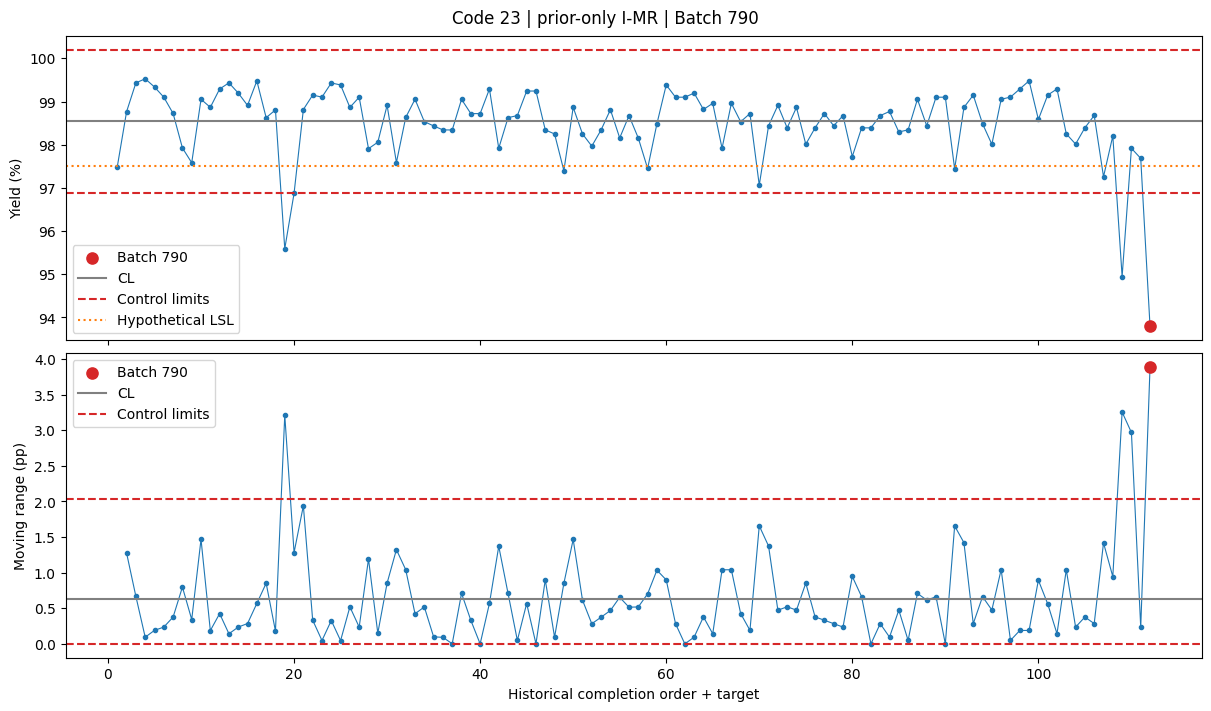

In [3]:
y=prior.tbl_yield
cl=float(y.mean()); sd=float(y.std()); mrbar=float(y.diff().abs().mean())
sigma=mrbar/1.128
assert sigma>0 and sd>0
lcl,ucl=cl-3*sigma,cl+3*sigma
mr_ucl=3.267*mrbar
seq=pd.concat([prior,target],ignore_index=True).sort_values(['end_ts','batch']).reset_index(drop=True)
v=seq.tbl_yield; diff=v.diff()
seq['mr']=diff.abs()
seq['r1_low']=v.lt(lcl); seq['r1_high']=v.gt(ucl)
seq['r2_low']=v.lt(cl).rolling(9).sum().eq(9); seq['r2_high']=v.gt(cl).rolling(9).sum().eq(9)
seq['r3_low']=diff.lt(0).rolling(5).sum().eq(5); seq['r3_high']=diff.gt(0).rolling(5).sum().eq(5)
seq['mr_high']=seq.mr.gt(mr_ucl)
seq['below_lsl']=v.lt(lsl)
t=seq[seq.batch.eq(BATCH)].iloc[0]
flags=['r1_low','r1_high','r2_low','r2_high','r3_low','r3_high','mr_high']
summary=pd.DataFrame([dict(code=CODE,batch=BATCH,phase=r.phase,start_ts=r.start_ts,end_ts=r.end_ts,actual=r.tbl_yield,old_lsl=float(old.lsl_q10),old_q10=float(old.q10),prior_n=len(prior),reference_n=len(ref),prior_mean=cl,prior_std=sd,prior_q10=q10,lsl=lsl,usl=usl,below_lsl=bool(t.below_lsl),below_exact_q10=bool(r.tbl_yield<q10),lsl_gap=max(lsl-r.tbl_yield,0),z_score=(r.tbl_yield-cl)/sd,reference_median=ref.tbl_yield.median(),cl=cl,lcl=lcl,ucl=ucl,mr=t.mr,mr_ucl=mr_ucl,**{f:bool(t[f]) for f in flags})])
summary.to_csv(OUT/'batch790_summary.csv',index=False); seq.to_csv(OUT/'spc_signals_code_23.csv',index=False)
display(summary.T)
x=np.arange(1,len(seq)+1)
fig,axs=plt.subplots(2,1,figsize=(12,7),sharex=True,layout='constrained')
for ax,values,center,lo,hi in [(axs[0],v,cl,lcl,ucl),(axs[1],seq.mr,mrbar,0,mr_ucl)]:
    ax.plot(x,values,'.-',lw=.8); ax.scatter(x[-1],values.iloc[-1],c='tab:red',s=65,label='Batch 790',zorder=5)
    ax.axhline(center,color='gray',label='CL'); ax.axhline(lo,color='tab:red',ls='--',label='Control limits'); ax.axhline(hi,color='tab:red',ls='--'); ax.legend(loc='best')
axs[0].axhline(lsl,color='tab:orange',ls=':',label='Hypothetical LSL'); axs[0].legend(loc='best'); axs[0].set_ylabel('Yield (%)'); axs[1].set_ylabel('Moving range (pp)'); axs[1].set_xlabel('Historical completion order + target'); fig.suptitle('Code 23 | prior-only I-MR | Batch 790')
fig.savefig(OUT/'imr_code_23_batch_790.png',dpi=160); plt.show(); plt.close(fig)

## 3. 원료 및 공정 집계 비교
기존 RCA의 median, Z-score, 역사 범위 및 IQR 비교를 유지한다. 원료, 공정, 생산 손실, 최종 품질을 분리한다. 결측 및 상수 변수는 확인 결과를 기록한다.

In [4]:
QUALITY_COLS=['Drug release average (%)','Drug release min (%)','Residual solvent','Total impurities','Impurity O','Impurity L']
LOSS_COLS=['total_waste','startup_waste']
RAW=['size','api_water','api_total_impurities','api_l_impurity','api_content','api_ps01','api_ps05','api_ps09','lactose_water','lactose_sieve0045','lactose_sieve015','lactose_sieve025','smcc_water','smcc_td','smcc_bd','smcc_ps01','smcc_ps05','smcc_ps09','starch_ph','starch_water']
base_cols=KEY+['tbl_yield']
def join(frame, keys):
    drop=['tbl_yield'] if 'tbl_yield' in frame else []
    return keys[base_cols].merge(frame.drop(columns=drop),on=KEY,validate='one_to_one',how='left',indicator=True).pipe(check_merge)
def check_merge(frame):
    assert frame['_merge'].eq('both').all()
    return frame.drop(columns='_merge')
ref_p=join(proc,ref); tar_p=join(proc,target)
ref_l=join(lab,ref); tar_l=join(lab,target)
ref_p.to_csv(OUT/'reference_code_23.csv',index=False); tar_p.to_csv(OUT/'target_code_23_batch_790.csv',index=False)
rows=[]; skipped=[]
def compare(a,b,features,source):
    for col in features:
        vals=pd.to_numeric(a[col],errors='coerce').replace([np.inf,-np.inf],np.nan).dropna(); value=pd.to_numeric(b[col],errors='coerce').iloc[0]
        if len(vals)<2 or not np.isfinite(value):
            skipped.append(dict(source=source,feature=col,reference_n=len(vals),target=value)); continue
        mean,median,std=vals.mean(),vals.median(),vals.std()
        q1,q3=vals.quantile(.25),vals.quantile(.75); iqr=q3-q1
        z=(value-mean)/std if std>0 else np.nan
        cat='raw_material' if source=='lab' else 'quality' if col in QUALITY_COLS else 'production_loss' if col in LOSS_COLS else 'process'
        rows.append(dict(code=CODE,batch=BATCH,source=source,category=cat,feature=col,reference_n=len(vals),reference_missing=len(a)-len(vals),mean=mean,median=median,std=std,minimum=vals.min(),maximum=vals.max(),target=value,difference=value-median,ratio=value/median if median!=0 else np.nan,z_score=z,abs_z_score=abs(z),q1=q1,q3=q3,iqr=iqr,iqr_lower=q1-1.5*iqr,iqr_upper=q3+1.5*iqr,outside_range=bool(value<vals.min() or value>vals.max()),iqr_outlier=bool(value<q1-1.5*iqr or value>q3+1.5*iqr) if iqr>0 else None))
compare(ref_l,tar_l,[c for c in RAW if c in ref_l],'lab')
compare(ref_p,tar_p,[c for c in ref_p if c not in KEY+['tbl_yield','weekend']],'process')
result=pd.DataFrame(rows).sort_values(['outside_range','abs_z_score'],ascending=False)
result.to_csv(OUT/'rca_comparison_code_23.csv',index=False)
pd.DataFrame(skipped,columns=['source','feature','reference_n','target']).to_csv(OUT/'skipped_variables.csv',index=False)
for cat,g in result.groupby('category'):
    print(cat); display(g[['feature','reference_n','median','target','z_score','outside_range','iqr_outlier']].head(12))

process


,feature,reference_n,median,target,z_score,outside_range,iqr_outlier
33,pre_CompForce_mean,102,0.000000,1.255718,27.620429,True,True
26,fom_change,102,12.000000,84.000000,12.770932,True,True
22,tbl_speed_0_duration,102,36.302083,215.000000,12.051068,True,True
31,main_CompForce_sd,102,0.109326,0.524694,8.065792,True,True
27,SREL_startup_mean,102,6.048346,35.433945,7.415610,True,True
21,tbl_speed_change,102,2.500000,19.687500,6.482019,True,True
45,Startup_tbl_fill_mean,102,6.197520,6.992527,2.781977,True,False
36,cyl_height_mean,102,2.070407,1.755271,-2.624598,True,True
35,tbl_fill_sd,102,0.082099,0.170540,2.961359,False,True
43,Startup_tbl_fill_maxDifference,102,0.490000,1.340000,2.778407,False,True


production_loss


,feature,reference_n,median,target,z_score,outside_range,iqr_outlier
23,total_waste,102,893.75,4083.854167,7.002727,True,True
24,startup_waste,102,7221.50,31712.000000,5.841086,True,True


quality


,feature,reference_n,median,target,z_score,outside_range,iqr_outlier
46,Drug release average (%),102,88.67,95.17,2.751976,True,False
47,Drug release min (%),102,83.00,91.00,2.294536,False,False
51,Impurity L,102,0.10,0.07,-1.605717,False,False
48,Residual solvent,102,0.01,0.06,0.865219,False,False
50,Impurity O,102,0.05,0.06,0.785669,False,False
49,Total impurities,102,0.26,0.25,-0.151645,False,False


raw_material


,feature,reference_n,median,target,z_score,outside_range,iqr_outlier
7,api_ps09,102,148.756,101.130,-2.434403,True,False
18,starch_ph,102,4.500,4.300,-1.999781,True,False
6,api_ps05,102,27.480,15.780,-1.593655,True,False
17,smcc_ps09,102,260.382,270.216,2.262940,False,True
5,api_ps01,102,1.460,1.200,-1.251066,False,False
11,lactose_sieve025,102,83.000,81.000,-1.231959,False,False
9,lactose_sieve0045,102,18.000,19.000,1.050631,False,False
10,lactose_sieve015,102,50.000,52.000,0.993292,False,False
15,smcc_ps01,102,32.585,31.123,-0.987664,False,False
16,smcc_ps05,102,122.547,124.841,0.860659,False,False


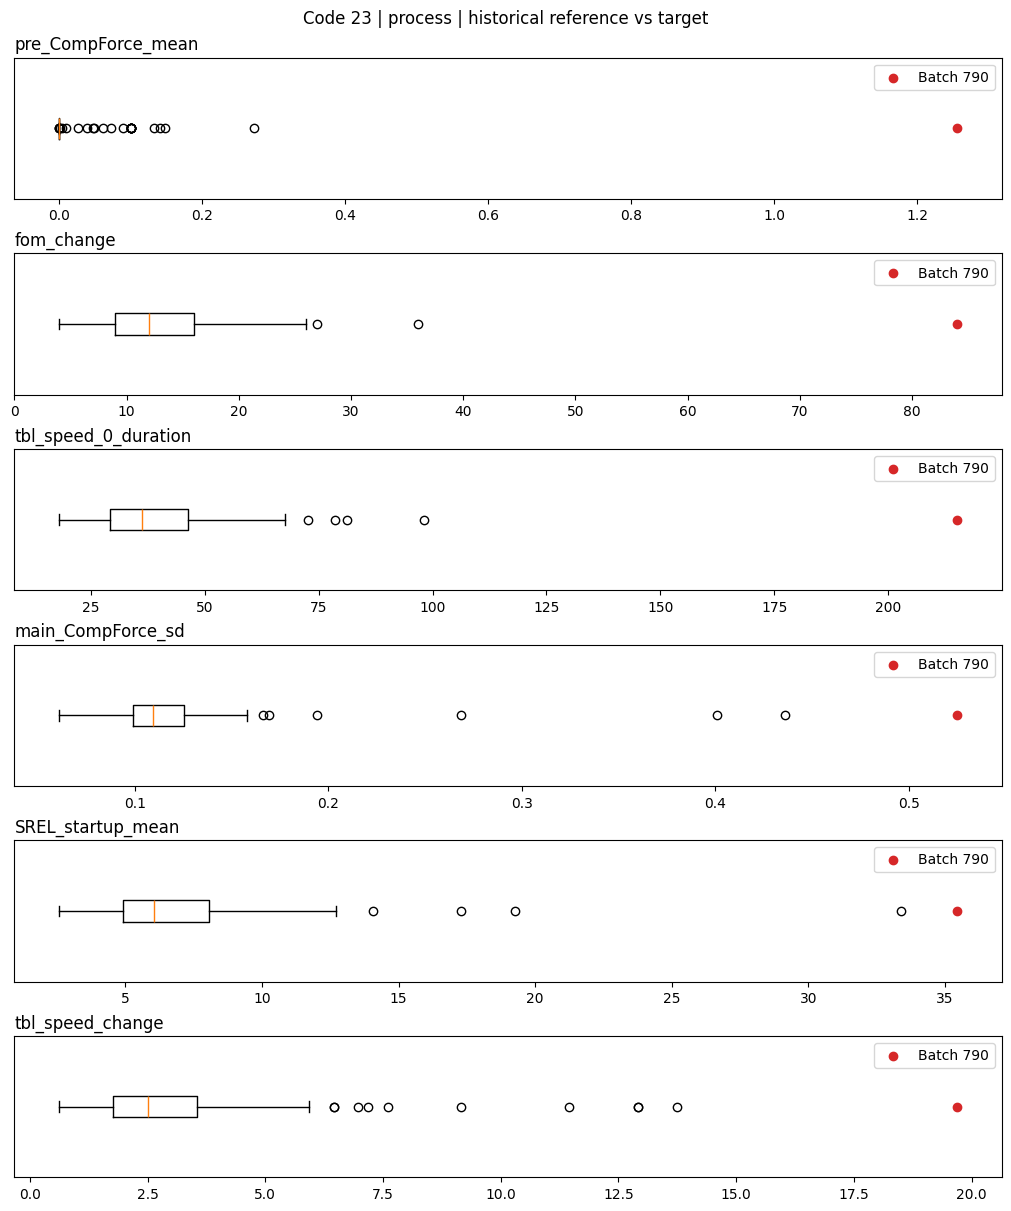

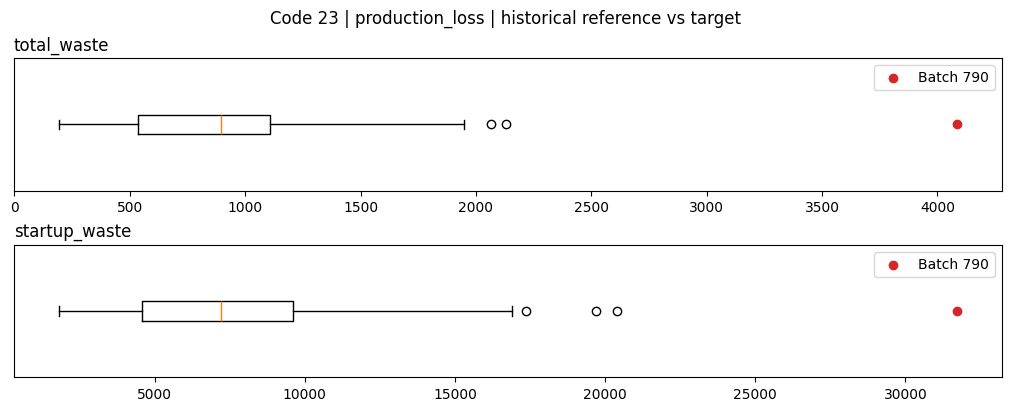

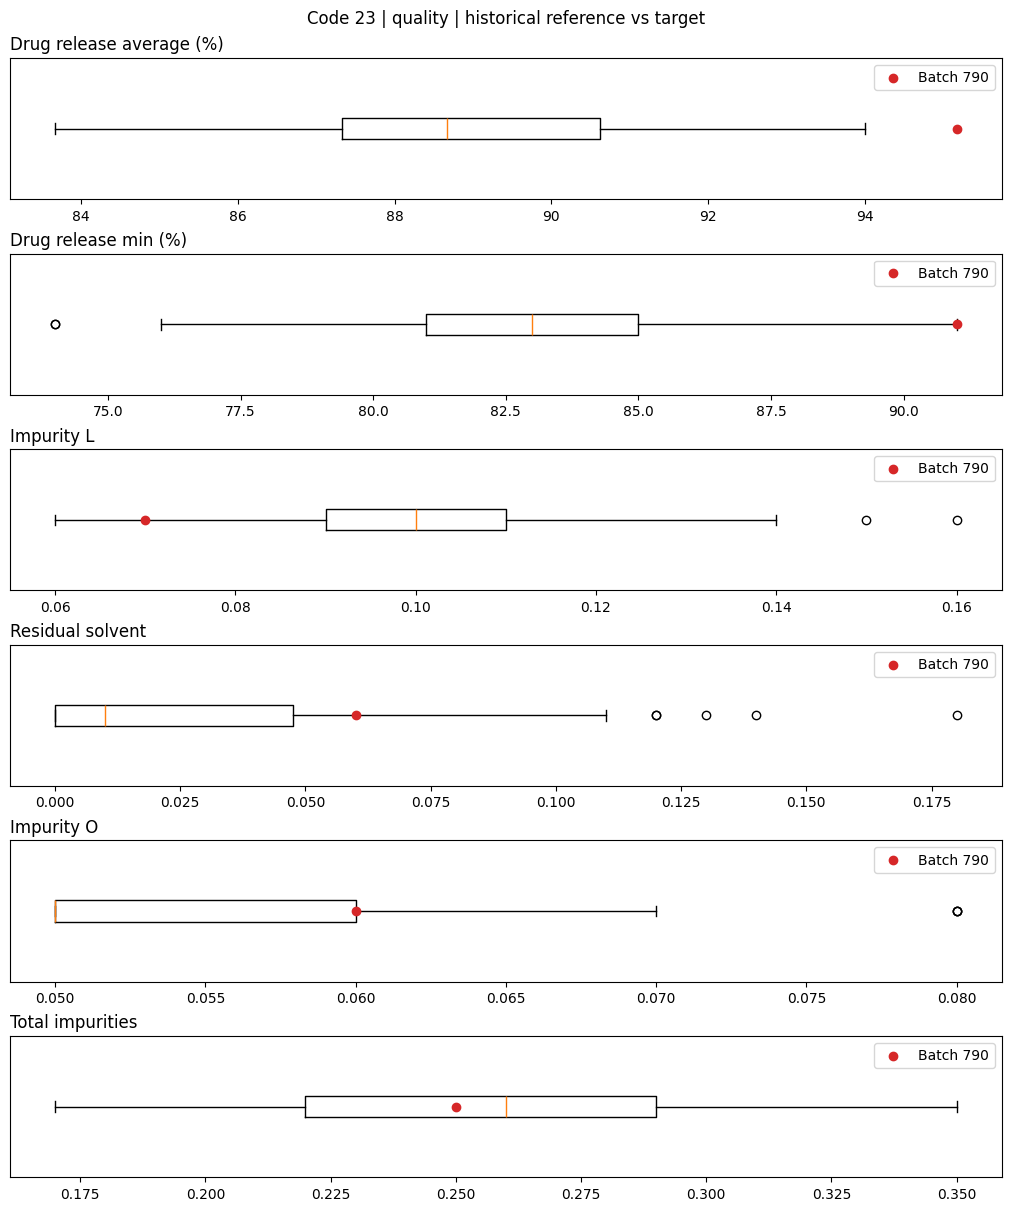

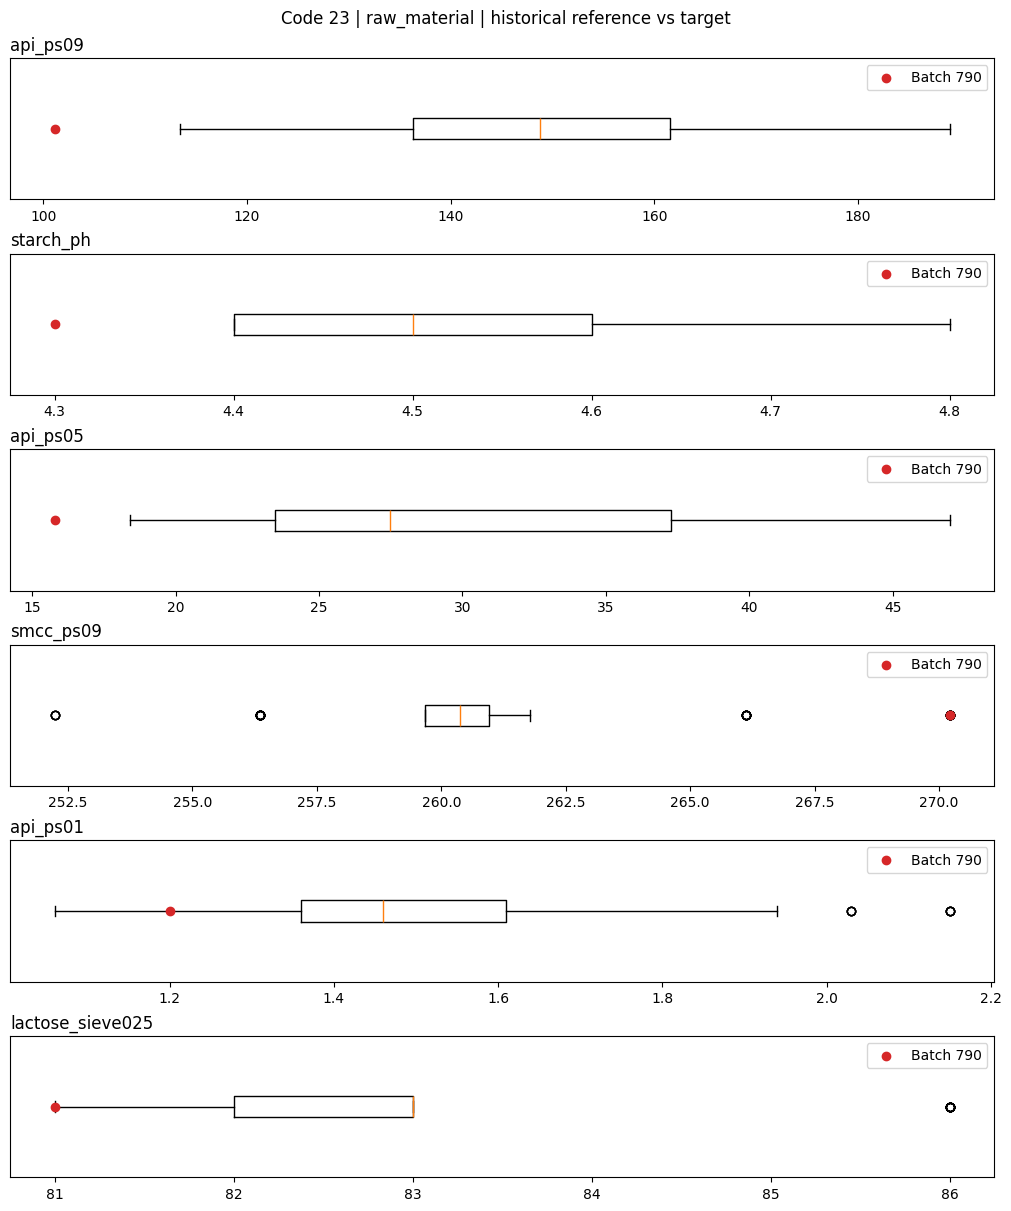

In [5]:
# 원인 후보를 비교할 수 있는 그래프. 단위가 다른 변수는 각각 별도 축.
for cat,g in result.groupby('category'):
    g=g.head(6)
    if g.empty: continue
    fig,axs=plt.subplots(len(g),1,figsize=(10,2.0*len(g)),squeeze=False,layout='constrained')
    for ax,(_,f) in zip(axs[:,0],g.iterrows()):
        a=ref_l if f.source=='lab' else ref_p
        vals=pd.to_numeric(a[f.feature],errors='coerce').replace([np.inf,-np.inf],np.nan).dropna()
        ax.boxplot(vals,vert=False); ax.scatter(f.target,1,c='tab:red',zorder=4,label='Batch 790'); ax.set_yticks([]); ax.set_title(f.feature,loc='left'); ax.legend(loc='best')
    fig.suptitle(f'Code 23 | {cat} | historical reference vs target')
    fig.savefig(OUT/f'boxplot_{cat}.png',dpi=150); plt.show(); plt.close(fig)

## 4. 원본 시계열 확인
timestamp가 같은 행도 삭제하지 않는다. 분 단위 중앙값과 범위는 시각화용이며 물리적 시간 가중 평균이 아니다. 폐기 카운터의 이름, 단위 및 리셋 처리 기준을 기존 코드로 확인한 뒤 손실량을 계산한다.

,code,batch,log_rows,unique_ts,repeated_timestamp_rows,duration_min,records_per_timestamp_median,zero_speed_row_pct
0,23,790,4938,824,4114,823.0,6.0,41.798299


Original columns: ['timestamp', 'campaign', 'batch', 'code', 'tbl_speed', 'fom', 'main_comp', 'tbl_fill', 'SREL', 'pre_comp', 'produced', 'waste', 'cyl_main', 'cyl_pre', 'stiffness', 'ejection']
Counter / waste candidate columns: ['waste']


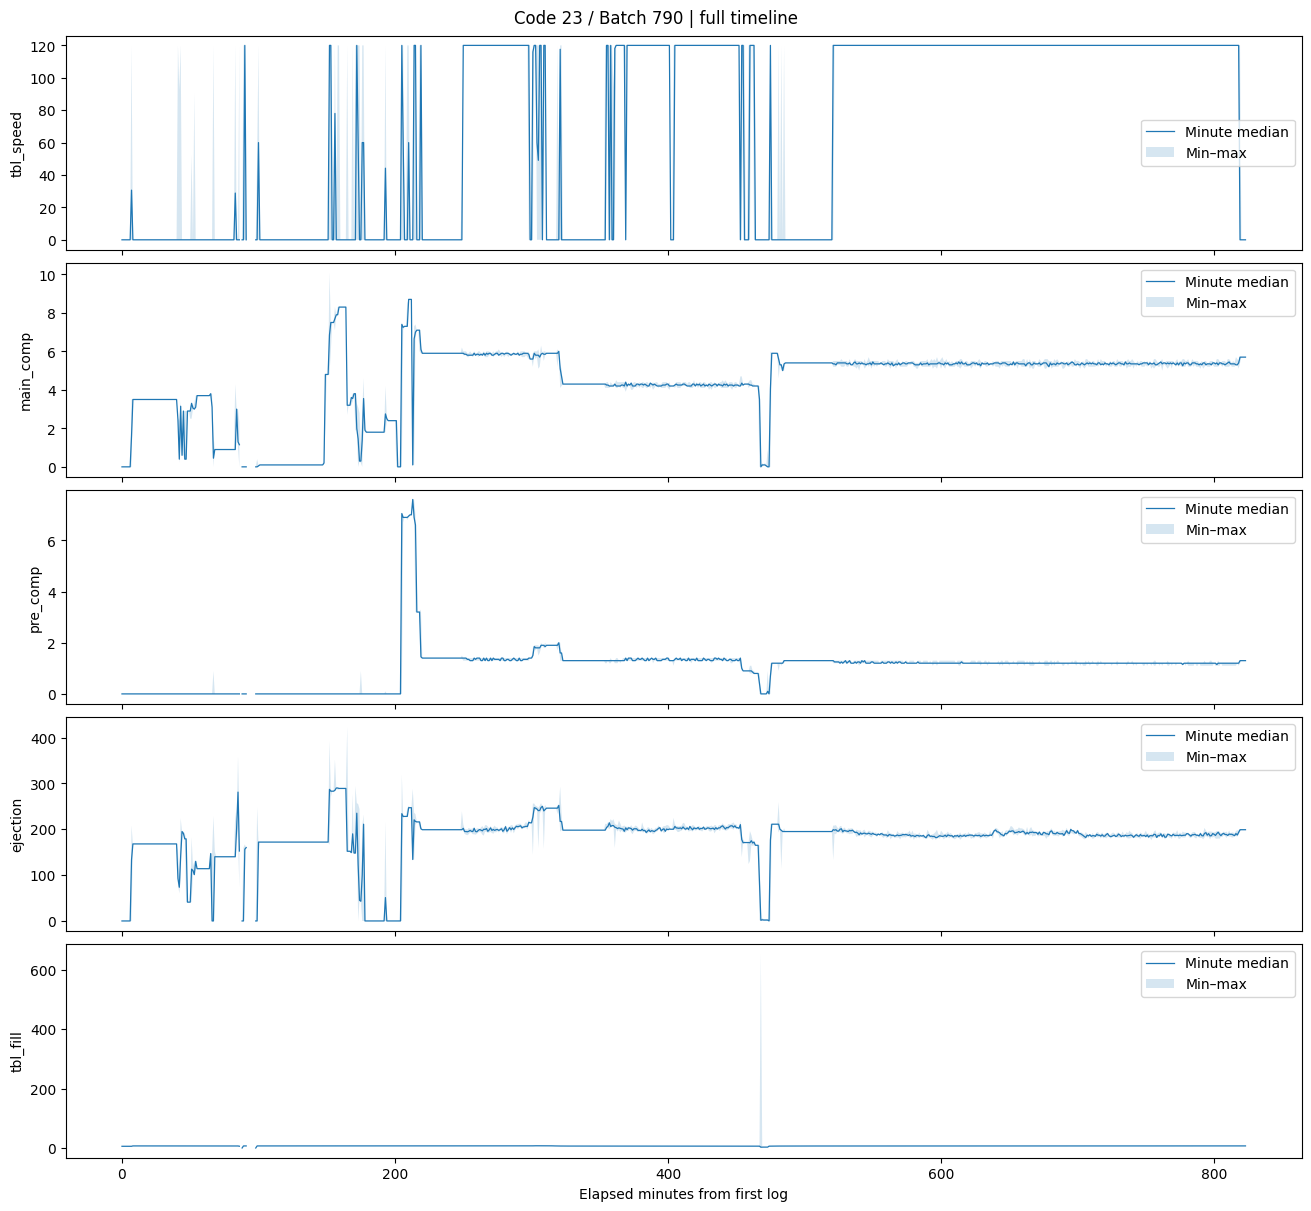

In [6]:
with ZipFile(DATA/'Process.zip') as z:
    d=pd.read_csv(z.open(f'Process/{CODE}.csv'),sep=';')
raw=d[d.batch.eq(BATCH)&d.code.eq(CODE)].copy()
assert len(raw)>0
raw['record_no']=np.arange(1,len(raw)+1)
a=pd.to_datetime(raw.timestamp.astype('string').str.strip(),format='%d%m%Y %H:%M',errors='coerce')
b=pd.to_datetime(raw.timestamp.astype('string').str.strip(),format='%Y-%m-%d %H:%M:%S',errors='coerce')
raw['ts']=a.fillna(b)
assert raw.ts.notna().all()
raw=raw.sort_values(['ts','record_no'],kind='stable').reset_index(drop=True)
raw['elapsed_min']=(raw.ts-raw.ts.min()).dt.total_seconds()/60
assert raw.ts.min()==r.start_ts and raw.ts.max()==r.end_ts
raw.to_csv(OUT/'timeseries_code_23_batch_790.csv',index=False)
sensor=[c for c in ['tbl_speed','main_comp','pre_comp','tbl_fill','SREL','fom','stiffness','ejection','cyl_main','cyl_pre'] if c in raw]
for c in sensor: raw[c]=pd.to_numeric(raw[c],errors='coerce')
minute=raw.groupby('elapsed_min')[sensor].agg(['median','min','max']); minute.columns=['_'.join(x) for x in minute.columns]; minute.to_csv(OUT/'timeseries_minute_summary.csv')
log_summary=pd.DataFrame([dict(code=CODE,batch=BATCH,log_rows=len(raw),unique_ts=raw.ts.nunique(),repeated_timestamp_rows=len(raw)-raw.ts.nunique(),duration_min=raw.elapsed_min.max(),records_per_timestamp_median=raw.groupby('ts').size().median(),zero_speed_row_pct=raw.tbl_speed.eq(0).mean()*100 if 'tbl_speed' in raw else np.nan)])
log_summary.to_csv(OUT/'timeseries_summary.csv',index=False); display(log_summary)
print('Original columns:',list(d.columns))
print('Counter / waste candidate columns:',[c for c in d if any(k in c.lower() for k in ['waste','count','reject','scrap','tablet','good'])])
plot_cols=[c for c in ['tbl_speed','main_comp','pre_comp','ejection','tbl_fill'] if c in sensor]
if plot_cols:
    fig,axs=plt.subplots(len(plot_cols),1,figsize=(13,2.4*len(plot_cols)),sharex=True,squeeze=False,layout='constrained')
    for ax,c in zip(axs[:,0],plot_cols):
        x=minute.index.to_numpy(dtype=float)
        ax.plot(x,minute[f'{c}_median'].to_numpy(dtype=float),lw=.9,label='Minute median')
        ax.fill_between(x,minute[f'{c}_min'].to_numpy(dtype=float),minute[f'{c}_max'].to_numpy(dtype=float),alpha=.18,label='Min–max')
        ax.set_ylabel(c); ax.legend(loc='best')
    axs[-1,0].set_xlabel('Elapsed minutes from first log'); fig.suptitle('Code 23 / Batch 790 | full timeline')
    fig.savefig(OUT/'rca_timeseries_code_23_full.png',dpi=150); plt.show(); plt.close(fig)

## 5. 실행 기록
이번 단계는 정상 비교군과 공정변수 후보의 확인까지다. 폐기량 집중 구간, 설비 정지 분류, ML 재예측 및 Agent JSON은 후속 단계에서 처리한다.

In [7]:
metadata=dict(revision='batch790_phase1',code=CODE,batch=BATCH,reference_policy='same product; end_ts strictly before target start_ts; valid yield',q10=float(q10),lsl=lsl,usl=usl,lsl_policy='exploratory floor Q10 to 0.5 pp; compare exact Q10 separately',actual_yield_release_time='unknown',python=sys.version,pandas=pd.__version__,numpy=np.__version__,sha256=hashes)
(OUT/'metadata.json').write_text(json.dumps(metadata,ensure_ascii=False,indent=2),encoding='utf-8')
print('Completed: batch790_phase1')
print('Output:',OUT)

Completed: batch790_phase1
Output: /Users/park-inki/Desktop/SKALA-yield-model/yield_experiment/results/revision_20261125/03_batch790_rca


## 6. 폐기 카운터 및 가동 상태 분석 (Phase 2 v3)
원본 행을 유지한다. 결측/음수는 미관측으로 처리한다. 인접한 유효 기록의 양의 차분만 시간별 집계에 사용한다. 결측 또는 시간 공백을 넘는 순변화는 별도 CSV에 기록하며 시간별 집계에는 포함하지 않는다. 가동/정지/미확인 3상태로 분리하며 확인된 정지-가동 전환만 재가동으로 계산한다. `counter_valid` / `speed_valid`는 완전성, `counter_usable` / `speed_usable`은 관측 자료 분석 가능성을 나타낸다. 양의 차분은 실제 물리적 폐기량이 아니며 결측에 따른 과소 집계 가능성이 있다.

In [8]:
P2=OUT/'phase2_v3'
P2.mkdir(exist_ok=True)
def pct(a,b):
    return float(100*a/b) if b>0 else np.nan

def analyze_log(frame):
    x=frame.copy().reset_index(drop=True)
    x['record_no']=np.arange(1,len(x)+1)
    a=pd.to_datetime(x.timestamp.astype('string').str.strip(),format='%d%m%Y %H:%M',errors='coerce')
    b=pd.to_datetime(x.timestamp.astype('string').str.strip(),format='%Y-%m-%d %H:%M:%S',errors='coerce')
    x['timestamp']=a.fillna(b)
    chronological=bool(x.timestamp.notna().all() and x.timestamp.is_monotonic_increasing)
    for col in ['waste','tbl_speed','main_comp','pre_comp','ejection','produced']:
        if col in x: x[col]=pd.to_numeric(x[col],errors='coerce').replace([np.inf,-np.inf],np.nan)
    x['waste']=x.waste.where(x.waste.ge(0))
    x['tbl_speed']=x.tbl_speed.where(x.tbl_speed.ge(0))
    x['elapsed_min']=(x.timestamp-x.timestamp.min()).dt.total_seconds()/60
    gap=x.timestamp.diff().dt.total_seconds().gt(60)
    wvalid=x.waste.notna(); svalid=x.tbl_speed.notna()
    adjacent=wvalid & wvalid.shift(1,fill_value=False) & ~gap & chronological
    x['waste_diff']=x.waste.diff().where(adjacent)
    x['waste_increment']=x.waste_diff.clip(lower=0)
    # Separate net changes across unavailable intervals; do not allocate to any time window.
    observed=x.loc[wvalid,['record_no','timestamp','waste']].copy()
    bridge=(observed.record_no.diff().gt(1)|observed.timestamp.diff().dt.total_seconds().gt(60))
    bridge_rows=observed.loc[bridge].copy()
    bridge_rows['from_record_no']=observed.record_no.shift().loc[bridge]
    bridge_rows['from_timestamp']=observed.timestamp.shift().loc[bridge]
    bridge_rows['from_waste']=observed.waste.shift().loc[bridge]
    bridge_rows['net_change']=observed.waste.diff().loc[bridge]
    x['bridge_net_change']=observed.waste.diff().where(bridge).reindex(x.index)
    x['state']=np.select([x.tbl_speed.gt(0),x.tbl_speed.eq(0)],['running','stopped'],default='unknown')
    x['running']=x.state.eq('running')
    x['segment_id']=(x.state.ne(x.state.shift())|gap).cumsum()
    x['window_start_min']=x.elapsed_min.floordiv(30)*30
    s=x.groupby('segment_id').agg(state=('state','first'),running=('running','first'),start_time=('timestamp','min'),end_time=('timestamp','max'),records=('record_no','size'),speed_median=('tbl_speed','median'),main_comp_mean=('main_comp','mean'),main_comp_std=('main_comp','std'),ejection_mean=('ejection','mean'),waste_increment=('waste_increment','sum'),observed_diff_n=('waste_diff','count')).reset_index()
    s['observed_span_min']=(s.end_time-s.start_time).dt.total_seconds()/60
    s['start_elapsed_min']=(s.start_time-x.timestamp.min()).dt.total_seconds()/60
    s['end_elapsed_min']=(s.end_time-x.timestamp.min()).dt.total_seconds()/60
    contiguous_prev=s.start_time.sub(s.end_time.shift()).dt.total_seconds().le(60)
    contiguous_next=s.start_time.shift(-1).sub(s.end_time).dt.total_seconds().le(60)
    s['confirmed_restart']=s.state.eq('running') & s.state.shift().eq('stopped') & contiguous_prev
    s['confirmed_internal_stop']=s.state.eq('stopped') & s.state.shift().eq('running') & s.state.shift(-1).eq('running') & contiguous_prev & contiguous_next
    runs=s[s.running]; stops=s[s.confirmed_internal_stop]
    total=x.waste_increment.sum(min_count=1)
    s['waste_share_pct']=s.waste_increment.map(lambda v:pct(v,total))
    first_run=x.loc[x.running,'timestamp'].min()
    early=x.elapsed_min.lt(90)
    first90=x.timestamp.ge(first_run)&x.timestamp.lt(first_run+pd.Timedelta(minutes=90))
    running=x.running
    run_age=(x.timestamp-x.groupby('segment_id').timestamp.transform('min')).dt.total_seconds()/60
    # Only observable stop-to-run transitions; unknown-to-run is not a confirmed restart.
    restart=running & x.segment_id.isin(s.loc[s.confirmed_restart,'segment_id']) & run_age.lt(5)
    # A difference is assigned to an operating state only if both adjacent states agree.
    x['waste_state']=x.state.where(x.state.eq(x.state.shift()) & adjacent,'unknown_or_transition')
    valid=bool(chronological and wvalid.all() and not gap.any() and x.waste.iloc[0]==0)
    speed_valid=bool(chronological and svalid.all() and not gap.any())
    usable=bool(chronological and adjacent.any())
    speed_usable=bool(chronological and svalid.any())
    def amount(mask): return x.loc[mask,'waste_increment'].sum() if usable else np.nan
    metrics=dict(counter_valid=valid,speed_valid=speed_valid,counter_usable=usable,speed_usable=speed_usable,chronological=chronological,log_rows=len(x),unique_ts=x.timestamp.nunique(),duration_min=x.elapsed_min.max(),gap_count=int(gap.sum()),waste_missing_n=int((~wvalid).sum()),speed_missing_n=int((~svalid).sum()),speed_observed_pct=pct(svalid.sum(),len(x)),adjacent_diff_n=int(adjacent.sum()),adjacent_diff_pct=pct(adjacent.sum(),max(0,len(x)-1)),initial_waste_counter=x.waste.iloc[0],max_waste_counter=x.waste.max(),total_positive_increments=total,counter_decrease_records=int(x.waste_diff.lt(0).sum()) if usable else np.nan,bridge_n=len(bridge_rows),bridge_positive_net_sum=bridge_rows.net_change.clip(lower=0).sum(),bridge_negative_net_sum=bridge_rows.net_change.clip(upper=0).sum(),zero_speed_record_pct=pct(x.tbl_speed.eq(0).sum(),svalid.sum()) if speed_usable else np.nan,internal_stop_count=len(stops) if speed_usable else np.nan,longest_stop_span_min=(stops.observed_span_min.max() if len(stops) else 0.) if speed_usable else np.nan,running_segment_count=len(runs) if speed_usable else np.nan,unknown_segment_count=int(s.state.eq('unknown').sum()),confirmed_restart_count=int(s.confirmed_restart.sum()),first_90min_waste=amount(early),first_90min_share_pct=pct(amount(early),total),first_running_90min_waste=amount(first90) if speed_usable and pd.notna(first_run) else np.nan,running_waste=amount(x.waste_state.eq('running')),zero_speed_waste=amount(x.waste_state.eq('stopped')),unknown_or_transition_waste=amount(x.waste_state.eq('unknown_or_transition')),restart_5min_running_record_share_pct=pct(restart.sum(),running.sum()) if speed_usable else np.nan,restart_5min_running_waste_share_pct=pct(amount(restart & x.waste_state.eq('running')),amount(x.waste_state.eq('running'))) if speed_usable else np.nan)
    return x,s,metrics

# Use original file order, not a previously aggregated minute-level table.
target_raw=d.loc[d.batch.eq(BATCH)&d.code.eq(CODE)].copy()
events,segments,target_metrics=analyze_log(target_raw)
assert target_metrics['counter_usable'], f"No usable adjacent counter differences: {target_metrics}"
assert target_metrics['speed_usable'], 'No usable speed observations'
print('Complete counter/speed coverage:',target_metrics['counter_valid'],target_metrics['speed_valid'])
assert np.isclose(sum(target_metrics[k] for k in ['running_waste','zero_speed_waste','unknown_or_transition_waste']),target_metrics['total_positive_increments'])
assert np.isclose(events.waste_increment.sum(),segments.waste_increment.sum())
events.to_csv(P2/'waste_events_code_23.csv',index=False)
events.loc[events.bridge_net_change.notna(),['record_no','timestamp','waste','bridge_net_change']].to_csv(P2/'counter_gap_bridges.csv',index=False)
events.loc[events.state.eq('unknown')|events.waste.isna()].to_csv(P2/'missing_log_rows.csv',index=False)
events.loc[events.waste_diff.lt(0)].to_csv(P2/'counter_decreases_code_23.csv',index=False)
segments.to_csv(P2/'operating_segments_code_23.csv',index=False)
waste_summary=pd.DataFrame([dict(code=CODE,batch=BATCH,**target_metrics)])
waste_summary.to_csv(P2/'waste_analysis_summary.csv',index=False)
display(waste_summary.T)

Complete counter/speed coverage: False False


,0
code,23
batch,790
counter_valid,False
speed_valid,False
counter_usable,True
speed_usable,True
chronological,True
log_rows,4938
unique_ts,824
duration_min,823.0


## 7. 집중 손실 구간 탐색 및 비교
기존 30분 구간 집계와 동일한 기준으로 폐기 카운터 증가량을 계산한다. 집중 구간은 최대 증가량을 보이는 연속 60분 후보로 자동 선정한다(사후 탐색, 원인 검증 아님). 실제 서비스의 고정 초기 30분 예측과는 무관하다.
집중 구간은 관측된 차분만 기준으로 선정하며, 결측으로 실제 최대 손실 구간과 다를 수 있다. 구간별 관측 수를 함께 기록한다.

In [9]:
total=target_metrics['total_positive_increments']
windows=events.groupby('window_start_min').agg(waste_increment=('waste_increment','sum'),records=('record_no','size'),observed_diff_n=('waste_diff','count'),speed_observed_n=('tbl_speed','count')).reset_index()
windows['start_time']=events.timestamp.min()+pd.to_timedelta(windows.window_start_min,unit='m')
windows['end_time']=windows.start_time+pd.Timedelta(minutes=30)
windows['share_pct']=windows.waste_increment.map(lambda v:pct(v,total))
assert np.isclose(windows.waste_increment.sum(),total)
windows.to_csv(P2/'waste_windows_code_23.csv',index=False)
display(windows.sort_values('waste_increment',ascending=False).head(10))
# Restrict to observed full 60-minute candidate windows. Include zero-increment bins.
starts=np.arange(0,max(1,int(events.elapsed_min.max()-60)+1),30)
scores=[events.loc[events.elapsed_min.ge(a)&events.elapsed_min.lt(a+60),'waste_increment'].sum() for a in starts]
focus_start=int(starts[int(np.argmax(scores))]); focus_end=focus_start+60
events['focus']=events.elapsed_min.ge(focus_start)&events.elapsed_min.lt(focus_end)
rows=[]
for label,g in [('Focus window',events[events.focus]),('Other periods',events[~events.focus])]:
    run=g[g.running]
    w=g.waste_increment.sum()
    rows.append(dict(period=label,records=len(g),running_records=len(run),zero_speed_pct=pct(g.tbl_speed.eq(0).sum(),g.tbl_speed.notna().sum()),speed_observed_n=int(g.tbl_speed.notna().sum()),unknown_speed_n=int(g.tbl_speed.isna().sum()),observed_diff_n=int(g.waste_diff.notna().sum()),bridge_n=int(g.bridge_net_change.notna().sum()),speed_mean=run.tbl_speed.mean(),speed_std=run.tbl_speed.std(),main_comp_mean=run.main_comp.mean(),main_comp_std=run.main_comp.std(),ejection_mean=run.ejection.mean(),ejection_std=run.ejection.std(),waste_increment=w,waste_share_pct=pct(w,total)))
focus=pd.DataFrame(rows)
assert np.isclose(focus.waste_increment.sum(),total)
focus.to_csv(P2/'focus_comparison_code_23.csv',index=False)
pd.DataFrame([dict(focus_start=focus_start,focus_end=focus_end,**rows[0])]).to_csv(P2/'focus_window_summary.csv',index=False)
display(focus.T)
print('Focus window:',focus_start,focus_end)
display(segments[segments.running].nlargest(10,'waste_increment'))
runs=segments[segments.running]
display(segments[segments.confirmed_internal_stop].nlargest(10,'observed_span_min'))

,window_start_min,waste_increment,records,observed_diff_n,speed_observed_n,start_time,end_time,share_pct
5,150.0,11623.0,180,180,180,2020-09-11 04:34:00,2020-09-11 05:04:00,21.912824
3,90.0,10691.0,180,135,136,2020-09-11 03:34:00,2020-09-11 04:04:00,20.155726
2,60.0,8300.0,180,168,169,2020-09-11 03:04:00,2020-09-11 03:34:00,15.647977
7,210.0,6657.0,180,180,180,2020-09-11 05:34:00,2020-09-11 06:04:00,12.550432
6,180.0,3800.0,180,180,180,2020-09-11 05:04:00,2020-09-11 05:34:00,7.164134
1,30.0,3046.0,180,180,180,2020-09-11 02:34:00,2020-09-11 03:04:00,5.742619
10,300.0,2676.0,180,180,180,2020-09-11 07:04:00,2020-09-11 07:34:00,5.045059
15,450.0,2194.0,180,180,180,2020-09-11 09:34:00,2020-09-11 10:04:00,4.136345
16,480.0,2021.0,180,180,180,2020-09-11 10:04:00,2020-09-11 10:34:00,3.810188
0,0.0,1110.0,179,178,179,2020-09-11 02:04:00,2020-09-11 02:34:00,2.092681


,0,1
period,Focus window,Other periods
records,360,4578
running_records,14,2805
zero_speed_pct,95.409836,38.728702
speed_observed_n,305,4578
unknown_speed_n,55,0
observed_diff_n,303,4577
bridge_n,2,0
speed_mean,109.328571,119.682068
speed_std,24.106221,4.459734


Focus window: 60 120


,segment_id,state,running,start_time,end_time,records,speed_median,main_comp_mean,main_comp_std,ejection_mean,waste_increment,observed_diff_n,observed_span_min,start_elapsed_min,end_elapsed_min,confirmed_restart,confirmed_internal_stop,waste_share_pct
59,60,running,True,2020-09-11 05:38:00,2020-09-11 05:39:00,10,120.0,6.860000,0.320416,222.300000,3212.0,10,1.0,214.0,215.0,True,False,6.055579
55,56,running,True,2020-09-11 05:29:00,2020-09-11 05:30:00,8,120.0,7.325000,0.148805,242.000000,2529.0,8,1.0,205.0,206.0,True,False,4.767920
47,48,running,True,2020-09-11 04:56:00,2020-09-11 04:57:00,7,120.0,2.657143,0.544234,245.285714,2137.0,7,1.0,172.0,173.0,True,False,4.028883
51,52,running,True,2020-09-11 05:00:00,2020-09-11 05:01:00,6,120.0,3.433333,0.904802,212.000000,1884.0,6,1.0,176.0,177.0,True,False,3.551902
61,62,running,True,2020-09-11 05:42:00,2020-09-11 05:43:00,5,120.0,6.140000,0.134164,203.200000,1627.0,5,1.0,218.0,219.0,True,False,3.067381
35,36,running,True,2020-09-11 04:36:00,2020-09-11 04:37:00,5,120.0,7.020000,0.690652,257.200000,1399.0,5,1.0,152.0,153.0,True,False,2.637533
57,58,running,True,2020-09-11 05:33:00,2020-09-11 05:34:00,4,120.0,8.625000,0.095743,246.000000,1325.0,4,1.0,209.0,210.0,True,False,2.498020
39,40,running,True,2020-09-11 04:42:00,2020-09-11 04:43:00,4,120.0,8.225000,0.150000,287.750000,1227.0,4,1.0,158.0,159.0,True,False,2.313261
27,28,running,True,2020-09-11 03:34:00,2020-09-11 03:34:00,4,120.0,0.000000,0.000000,158.250000,1211.0,4,0.0,90.0,90.0,True,False,2.283096
105,106,running,True,2020-09-11 09:59:00,2020-09-11 09:59:00,4,120.0,4.975000,1.078193,194.000000,1180.0,4,0.0,475.0,475.0,True,False,2.224652


,segment_id,state,running,start_time,end_time,records,speed_median,main_comp_mean,main_comp_std,ejection_mean,waste_increment,observed_diff_n,observed_span_min,start_elapsed_min,end_elapsed_min,confirmed_restart,confirmed_internal_stop,waste_share_pct
32,33,stopped,False,2020-09-11 03:44:00,2020-09-11 04:36:00,310,0.0,0.372581,1.080299,172.000000,568.0,310,52.0,100.0,152.0,False,True,1.070850
112,113,stopped,False,2020-09-11 10:09:00,2020-09-11 10:45:00,213,0.0,5.400000,0.000000,195.000000,41.0,213,36.0,485.0,521.0,False,True,0.077297
2,3,stopped,False,2020-09-11 02:11:00,2020-09-11 02:44:00,199,0.0,3.500000,0.000000,168.000000,292.0,199,33.0,7.0,40.0,False,True,0.550507
80,81,stopped,False,2020-09-11 07:26:00,2020-09-11 07:58:00,191,0.0,4.300000,0.000000,198.000000,124.0,191,32.0,322.0,354.0,False,True,0.233777
62,63,stopped,False,2020-09-11 05:43:00,2020-09-11 06:13:00,181,0.0,5.900000,0.000000,199.000000,102.0,181,30.0,219.0,249.0,False,True,0.192300
52,53,stopped,False,2020-09-11 05:01:00,2020-09-11 05:17:00,96,0.0,1.839583,0.257714,2.291667,238.0,96,16.0,177.0,193.0,False,True,0.448701
18,19,stopped,False,2020-09-11 03:12:00,2020-09-11 03:27:00,93,0.0,0.900000,0.000000,140.258065,250.0,93,15.0,68.0,83.0,False,True,0.471325
16,17,stopped,False,2020-09-11 02:57:00,2020-09-11 03:11:00,84,0.0,3.438095,0.785088,103.547619,263.0,84,14.0,53.0,67.0,False,True,0.495833
104,105,stopped,False,2020-09-11 09:47:00,2020-09-11 09:59:00,70,0.0,1.504286,1.956293,55.357143,0.0,70,12.0,463.0,475.0,False,True,0.000000
54,55,stopped,False,2020-09-11 05:18:00,2020-09-11 05:29:00,67,0.0,1.655224,1.127250,0.044776,52.0,67,11.0,194.0,205.0,False,True,0.098036


## 8. 과거 정상 비교군의 동일 지표 산출
102개 비교군에 같은 분석 규칙을 적용한다. 원본 로그 순서, 카운터 유효성, 속도 유효성을 기록하고 유효한 관측만 통계에 사용한다. 분 단위 기록이므로 정지 구간의 observed span은 실제 정지시간과 다를 수 있다.
완전한 배치뿐 아니라 부분 관측 배치도 동일 규칙으로 분석한다. 관측률과 완전성은 별도 표시하며, 결측률이 다르면 증가량과 정지 횟수 비교에 편향이 있을 수 있다.

In [10]:
hist=[]
for bid in ref.batch:
    g=d.loc[d.batch.eq(bid)&d.code.eq(CODE)]
    if g.empty:
        hist.append(dict(code=CODE,batch=int(bid),group='reference',counter_valid=False,speed_valid=False)); continue
    _,_,m=analyze_log(g)
    hist.append(dict(code=CODE,batch=int(bid),group='reference',**m))
reference_ts=pd.DataFrame(hist+[dict(code=CODE,batch=BATCH,group='target',**target_metrics)])
reference_ts.to_csv(P2/'reference_timeseries_code_23.csv',index=False)
hist_ref=reference_ts[reference_ts.group.eq('reference')]
metrics=['duration_min','speed_observed_pct','adjacent_diff_pct','zero_speed_record_pct','internal_stop_count','longest_stop_span_min','running_segment_count','total_positive_increments','first_90min_share_pct','restart_5min_running_record_share_pct','restart_5min_running_waste_share_pct']
comp=[]
for metric in metrics:
    vals=pd.to_numeric(hist_ref[metric],errors='coerce').dropna()
    val=target_metrics[metric]
    if len(vals)<2 or not np.isfinite(val): continue
    mean,sd=vals.mean(),vals.std()
    comp.append(dict(metric=metric,reference_n=len(vals),complete_counter_reference_n=int(hist_ref.counter_valid.sum()),complete_speed_reference_n=int(hist_ref.speed_valid.sum()),mean=mean,median=vals.median(),std=sd,minimum=vals.min(),maximum=vals.max(),q05=vals.quantile(.05),q95=vals.quantile(.95),target=val,z_score=(val-mean)/sd if sd>0 else np.nan,outside_range=bool(val<vals.min() or val>vals.max())))
historical=pd.DataFrame(comp)
historical.to_csv(P2/'reference_ts_comparison_code_23.csv',index=False)
display(historical)
print('Reference batches:',len(hist_ref),'Valid counter:',hist_ref.counter_valid.sum(),'Valid speed:',hist_ref.speed_valid.sum())

,metric,reference_n,complete_counter_reference_n,complete_speed_reference_n,mean,median,std,minimum,maximum,q05,q95,target,z_score,outside_range
0,duration_min,102,97,98,555.147059,531.500000,254.023753,439.000000,3068.000000,456.000000,586.950000,823.000000,1.054441,False
1,speed_observed_pct,102,97,98,99.952124,100.000000,0.323615,97.047303,100.000000,100.000000,100.000000,98.886189,-3.293839,False
2,adjacent_diff_pct,102,97,98,99.951211,100.000000,0.326873,97.016275,100.000000,100.000000,100.000000,98.845453,-3.382834,False
3,zero_speed_record_pct,102,97,98,12.518984,10.986407,7.973124,6.598407,84.423202,7.710094,18.512361,42.269097,3.731299,False
4,internal_stop_count,102,97,98,11.205882,9.000000,9.677307,1.000000,57.000000,3.000000,28.000000,52.000000,4.215441,False
5,longest_stop_span_min,102,97,98,53.568627,28.000000,241.604066,7.000000,2468.000000,18.000000,46.800000,52.000000,-0.006493,False
6,running_segment_count,102,97,98,12.235294,10.000000,9.673048,2.000000,58.000000,4.000000,29.000000,55.000000,4.421017,False
7,total_positive_increments,102,97,98,8580.323529,8580.000000,4406.514179,1845.000000,20453.000000,2445.500000,16945.000000,53042.000000,10.089988,True
8,first_90min_share_pct,102,97,98,91.241401,96.230984,13.643723,27.994027,99.795884,58.132633,99.585661,23.483277,-4.966249,True
9,restart_5min_running_record_share_pct,102,97,98,5.666383,4.021867,5.345451,1.163201,32.382964,1.528396,14.552253,12.096488,1.202912,False


Reference batches: 102 Valid counter: 97 Valid speed: 98


## 9. 집중 구간 및 비교 그래프

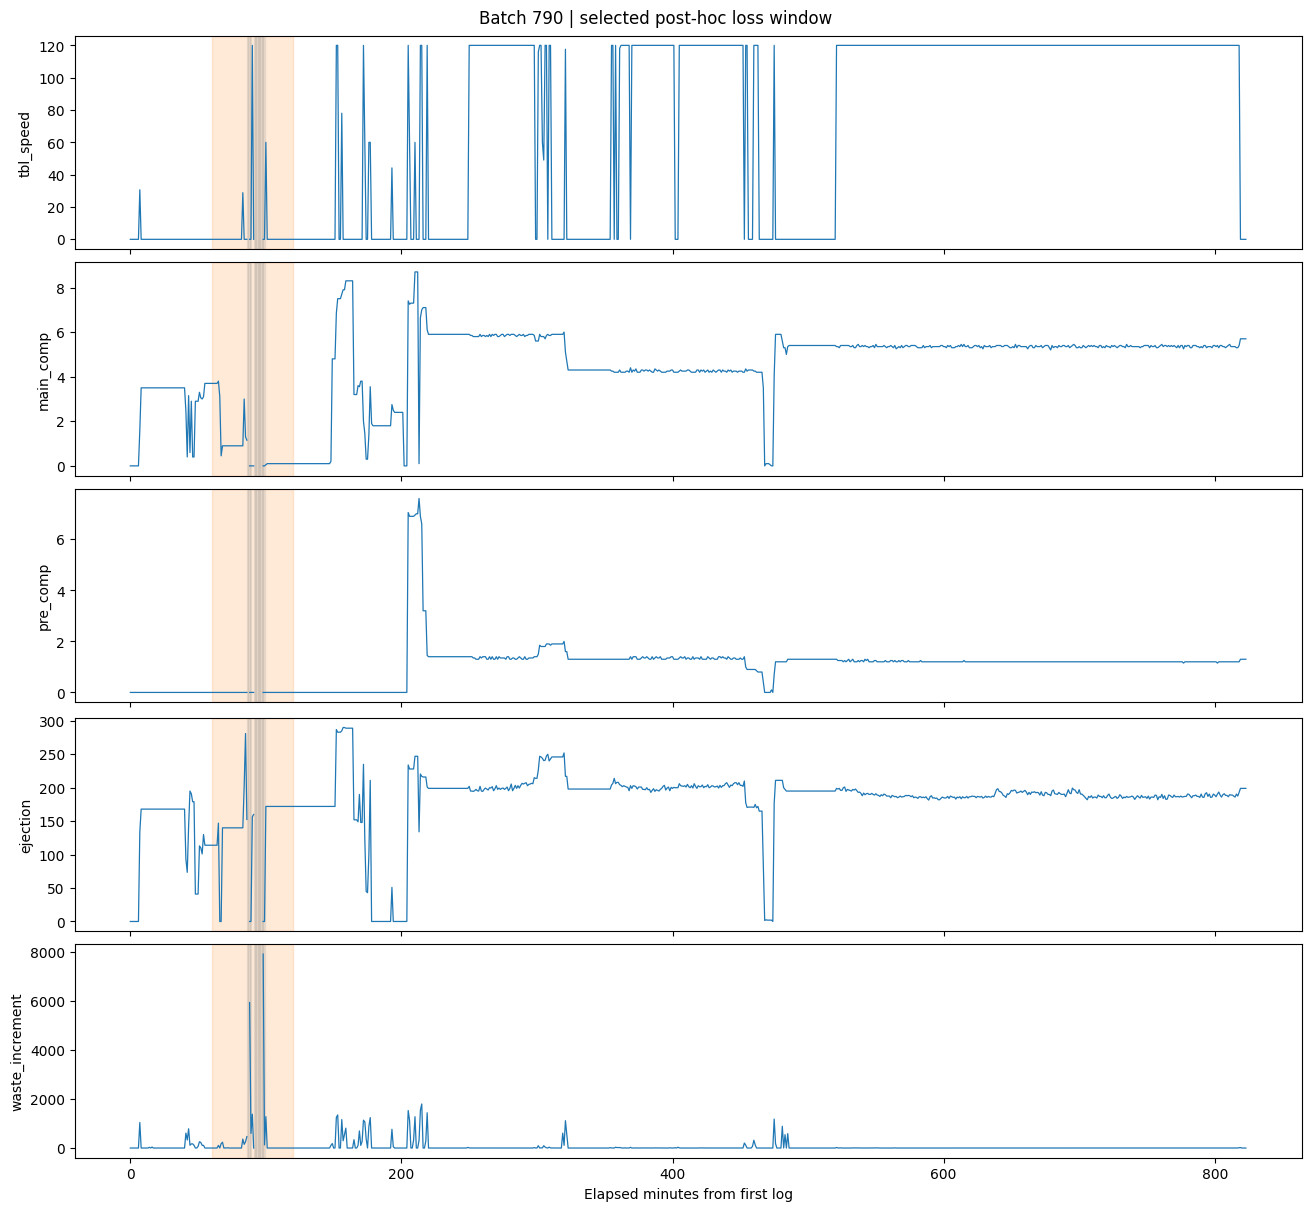

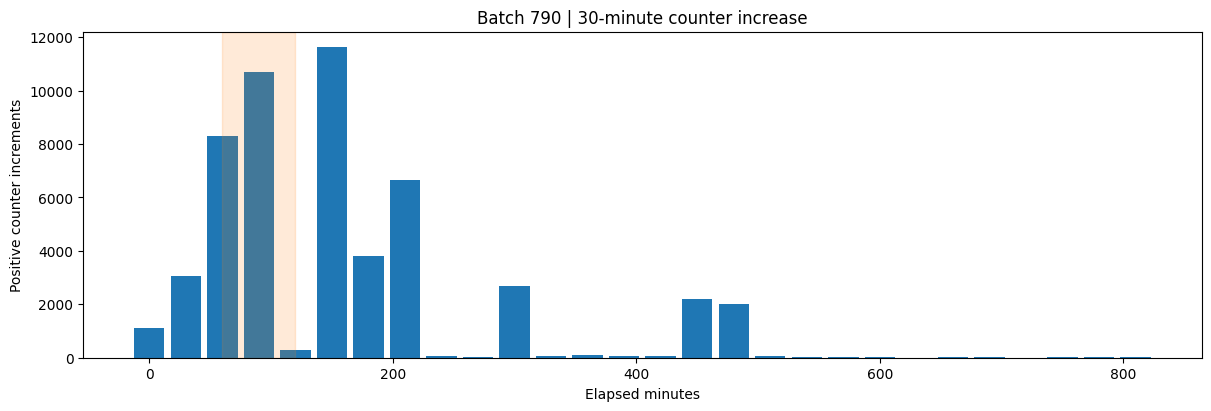

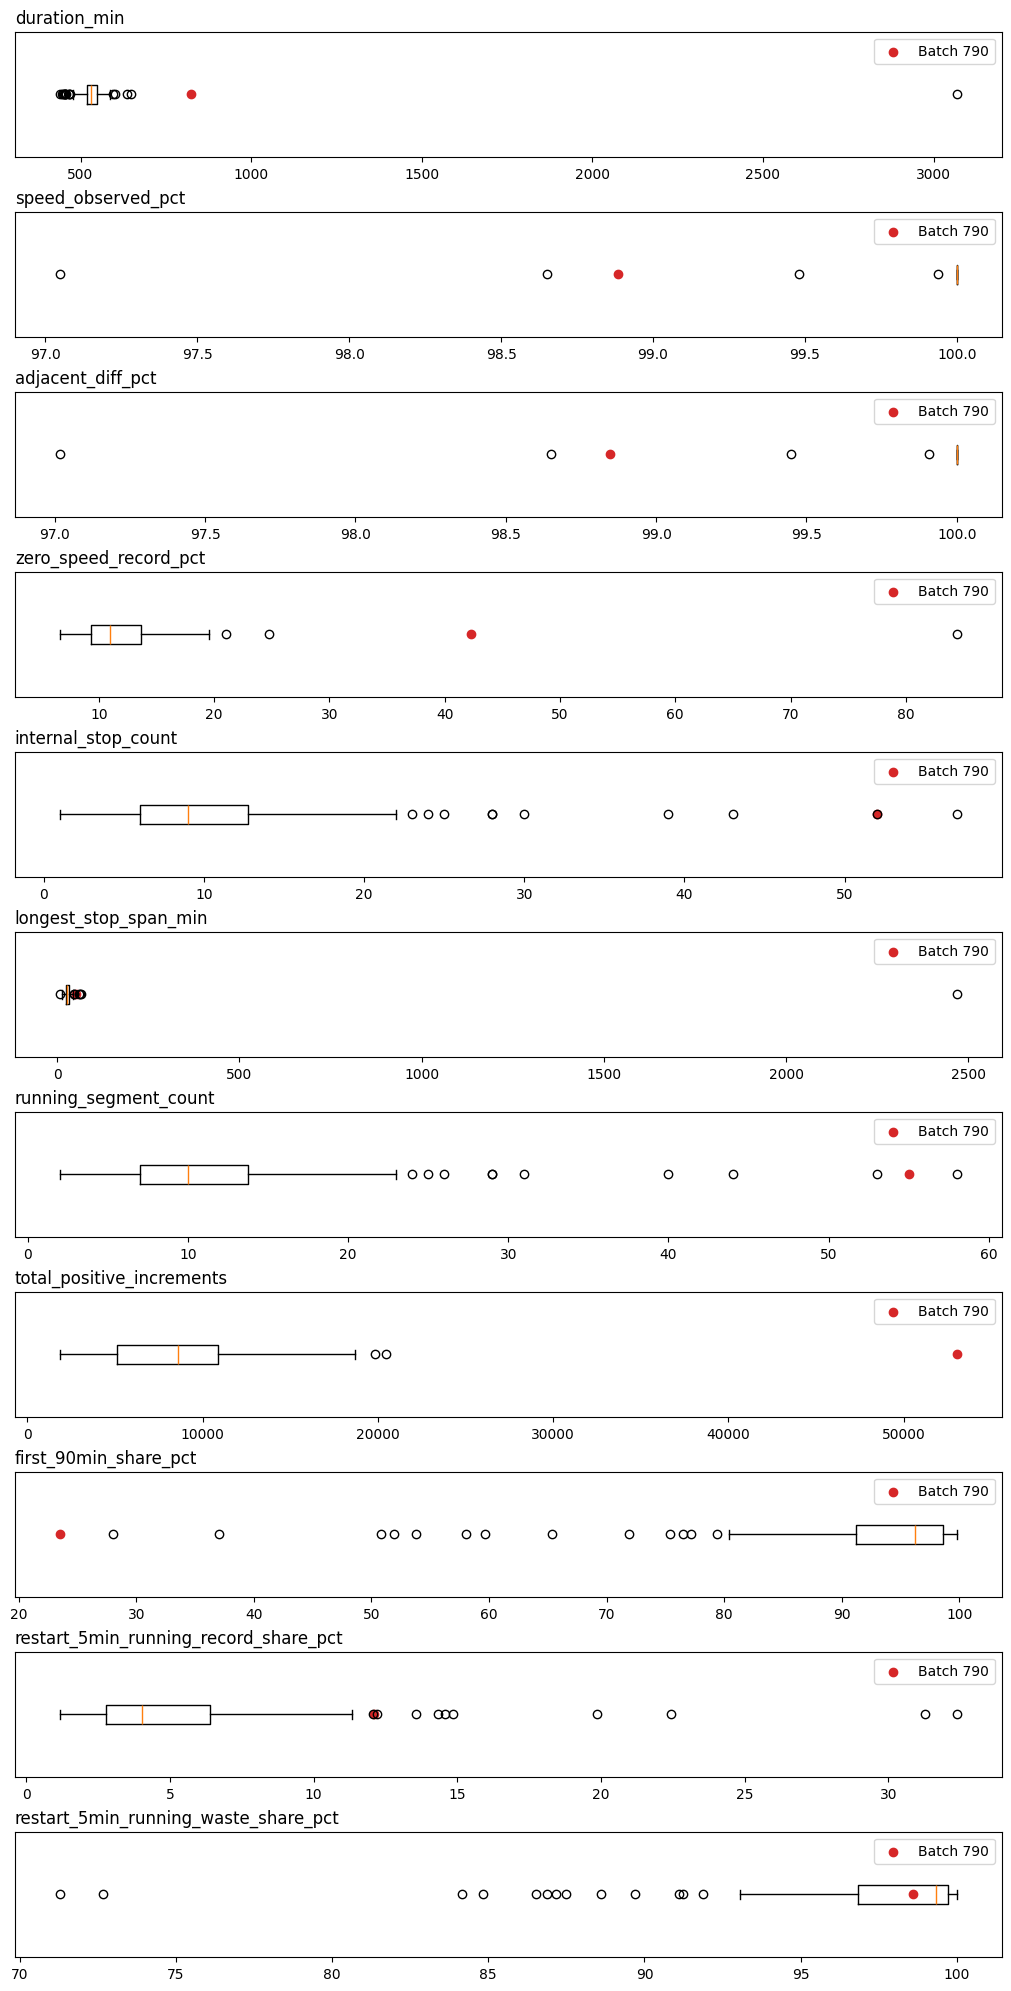

In [11]:
fig,axs=plt.subplots(5,1,figsize=(13,12),sharex=True,layout='constrained')
for ax,c in zip(axs,['tbl_speed','main_comp','pre_comp','ejection','waste_increment']):
    agg=events.groupby('elapsed_min')[c].sum(min_count=1) if c=='waste_increment' else events.groupby('elapsed_min')[c].median()
    ax.plot(agg.index,agg.values,lw=.9)
    ax.axvspan(focus_start,focus_end,alpha=.16,color='tab:orange')
    for minute in events.loc[events.state.eq('unknown')|events.waste.isna(),'elapsed_min'].unique():
        ax.axvspan(minute,minute+1,alpha=.12,color='tab:gray')
    ax.set_ylabel(c)
axs[-1].set_xlabel('Elapsed minutes from first log')
fig.suptitle('Batch 790 | selected post-hoc loss window')
fig.savefig(P2/'rca_timeseries_code_23_focus.png',dpi=150); plt.show(); plt.close(fig)
fig,ax=plt.subplots(figsize=(12,4),layout='constrained')
ax.bar(windows.window_start_min,windows.waste_increment,width=25)
ax.axvspan(focus_start,focus_end,alpha=.16,color='tab:orange')
ax.set(xlabel='Elapsed minutes',ylabel='Positive counter increments',title='Batch 790 | 30-minute counter increase')
fig.savefig(P2/'waste_windows_code_23.png',dpi=150); plt.show(); plt.close(fig)
if len(historical):
    fig,axs=plt.subplots(len(historical),1,figsize=(10,1.8*len(historical)),squeeze=False,layout='constrained')
    for ax,(_,h) in zip(axs[:,0],historical.iterrows()):
        vals=hist_ref[h.metric].dropna()
        ax.boxplot(vals,vert=False); ax.scatter(h.target,1,c='tab:red',label='Batch 790'); ax.set_yticks([]); ax.set_title(h.metric,loc='left'); ax.legend(loc='best')
    fig.savefig(P2/'reference_timeseries_boxplot.png',dpi=150); plt.show(); plt.close(fig)

## 10. RCA Agent JSON 초안 (기존 0.2.0 구조 참고)
기존 JSON의 주요 키를 유지하되 분석 대상이 기존 train이라는 점과 과거 배치만 활용한 별도 기준을 명시한다. 원인 후보는 미확정이며, 실제 기존 Agent의 스키마 검증기와의 호환 여부는 별도 확인이 필요하다. 기존 789/799 산출물은 변경하지 않는다.

In [12]:
def records(df):
    return json.loads(df.to_json(orient='records',date_format='iso',double_precision=15))
def one(df):
    assert len(df)==1
    return records(df)[0]
def indexed(df,key):
    assert df[key].is_unique
    return {str(row[key]):row for row in records(df)}
s0=one(summary); ts0=one(log_summary)
process_features=result[result.category.eq('process')]
ref_summary=dict(code=CODE,batch=BATCH,train_n=len(prior),reference_n=len(ref),excluded_n=len(prior)-len(ref),lsl=lsl,usl=usl,reference_yield_mean=float(ref.tbl_yield.mean()),reference_yield_median=float(ref.tbl_yield.median()),reference_yield_std=float(ref.tbl_yield.std()),target_yield=float(r.tbl_yield))
def hyp(n,title,evidence,counter,checks):
    return dict(id=f'H{n}',priority=n,title=title,status='unconfirmed',evidence_paths=evidence,counterevidence=counter,required_checks=checks)
hypotheses=[
hyp(1,'타정 속도 변화 및 정지·재가동 조건 조사',['/feature_comparison/all_features/tbl_speed_change','/feature_comparison/all_features/tbl_speed_0_duration','/timeseries/historical_comparison'],['정지 기록이 고장이나 원인을 입증하지 않음'],['설비 알람과 작업자 기록','정지 및 재가동 사유']),
hyp(2,'예압축력 조건 및 주압축력 변동 조사',['/feature_comparison/all_features/pre_CompForce_mean','/feature_comparison/all_features/main_CompForce_sd','/timeseries/focus_comparison'],['과거 관측 범위는 승인 설정 범위가 아님'],['승인 레시피 및 압축력 설정 이력']),
hyp(3,'생산 손실 기록 및 집중 구간 조사',['/feature_comparison/all_features/startup_waste','/timeseries/priority_window','/timeseries/waste_summary'],['양의 카운터 차분은 실제 폐기 발생 시점 또는 수량으로 검증되지 않음'],['카운터 단위와 리셋 이력','실제 폐기 및 수율 산정 기록']),
hyp(4,'원료 API 입도 차이 조사',['/feature_comparison/all_features/api_ps09','/feature_comparison/all_features/api_ps05'],['두 입도 변수는 IQR 기준 이상치로 분류되지 않음'],['원료 LOT와 승인 원료 규격','입도 차이와 타정 조건 관계'])
]
graphs=[OUT/'imr_code_23_batch_790.png',OUT/'boxplot_process.png',OUT/'rca_timeseries_code_23_full.png',P2/'rca_timeseries_code_23_focus.png',P2/'waste_windows_code_23.png',P2/'reference_timeseries_boxplot.png']
source_paths=[OUT/'batch790_summary.csv',OUT/'historical_reference_selection.csv',OUT/'rca_comparison_code_23.csv',OUT/'timeseries_summary.csv',P2/'waste_analysis_summary.csv',P2/'focus_comparison_code_23.csv',P2/'focus_window_summary.csv',P2/'operating_segments_code_23.csv',P2/'waste_windows_code_23.csv',P2/'reference_ts_comparison_code_23.csv',P2/'reference_timeseries_code_23.csv',P2/'counter_gap_bridges.csv',P2/'missing_log_rows.csv']
fr=one(focus[focus.period.eq('Focus window')])
json_result=dict(
 schema_version='0.2.0',case_id='code23_batch790',scenario_type='retrospective_demo',
 batch_info=dict(code=CODE,batch=BATCH,start=str(r.start_ts),end=str(r.end_ts),actual_yield_pct=float(r.tbl_yield),analysis_phase='train',reference_policy='prior-only retrospective case; not original test'),
 specification=dict(status='research_poc_only',approved_manufacturing_spec=False,configuration='prior-only Q10 floored to 0.5 pp',configuration_version='batch790_phase2_v3',lsl_pct=lsl,usl_pct=usl,actual_pct=float(r.tbl_yield),spec_outside=bool(s0['below_lsl']),gap_below_lsl_pp=s0['lsl_gap'],actual_gmp_oos=None,newly_detected=None,exact_q10=s0['prior_q10'],old_lsl=s0['old_lsl']),
 spc=dict(signals=dict(i_low=s0['r1_low'],i_high=s0['r1_high'],mr_signal=s0['mr_high'],**{k:s0[k] for k in ['r2_low','r2_high','r3_low','r3_high']}),limits=dict(i_lcl=s0['lcl'],i_ucl=s0['ucl'],mr_ucl=s0['mr_ucl']),observations=dict(mr=s0['mr'],yield_z_score=s0['z_score'],training_mean=s0['prior_mean'],training_std=s0['prior_std']),interpretation='SPC signals support investigation, not causality.'),
 reference=dict(selection='Same product, completed before target first log, within hypothetical limits',count=len(ref),summary=ref_summary,timeseries_reference_count=int(hist_ref.log_rows.notna().sum()),valid_waste_reference_count=int(hist_ref.counter_valid.sum()),usable_waste_reference_count=int(hist_ref.counter_usable.fillna(False).sum()),approved_normal_status_verified=False),
 feature_comparison=dict(compared_features=len(result),process_feature_count=len(process_features),outside_reference_range_count=int(process_features.outside_range.sum()),process_iqr_outlier_count=int(process_features.iqr_outlier.eq(True).sum()),process_abs_z_ge_3_count=int(process_features.abs_z_score.ge(3).sum()),all_features=indexed(result,'feature'),warning='Descriptive comparison, not causal or approved limits.'),
 timeseries=dict(timestamp_resolution='minute',summary=ts0,target_statistics=one(reference_ts[reference_ts.group.eq('target')]),waste_summary=one(waste_summary),priority_window=dict(start_elapsed_min=focus_start,end_elapsed_min_exclusive=focus_end,waste_increment=fr['waste_increment'],waste_share_pct=fr['waste_share_pct']),focus_comparison=indexed(focus,'period'),historical_comparison=indexed(historical,'metric'),top_running_segments=records(segments[segments.running].nlargest(10,'waste_increment')),window_summary=records(windows),counter_warning='Only adjacent observed positive differences are included; missing-interval net changes are excluded from windows. Observed increments are not verified physical waste or final yield. Unknown speed is not stopped; restart counts require observed stop-to-run transitions.'),
 ml_prediction=dict(status='not_evaluated_in_q10_scenario',included=False),shap=dict(status='not_evaluated_in_q10_scenario',included=False),uncertainty=dict(status='not_evaluated_in_q10_scenario',included=False),
 hypotheses=hypotheses,references=[],limitations=dict(confirmed_root_cause=None,causality_established=False,human_review_required=True,approved_specifications_available=False,autonomous_recipe_change_allowed=False,autonomous_batch_release_allowed=False,automatic_capa_execution_allowed=False,warnings=['Target originally in train; not independent test evidence.','Focus window selected retrospectively.','Zero speed does not establish failure.','Observed segment spans are not exact stop durations.','Yield release time unknown.','Agent integration schema not yet externally validated.','Missing observations can underestimate counter increments and stop/restart counts; focus selection uses observed increments only.','Zero-speed record percentage uses valid speed observations only.']),
 artifacts=dict(graphs=[str(q.relative_to(ROOT)) for q in graphs if q.exists()]),
 provenance={str(q.relative_to(ROOT)):{'sha256':hashlib.sha256(q.read_bytes()).hexdigest()} for q in source_paths+graphs if q.exists()}
)
# Validate all evidence paths; do not claim compatibility with external validator.
for h in hypotheses:
    for pointer in h['evidence_paths']:
        node=json_result
        for key in pointer.strip('/').split('/'):
            node=node[key]
assert json_result['reference']['count']==len(ref)
assert BATCH not in ref.batch.values
assert np.isclose(windows.waste_increment.sum(),total)
assert np.isclose(segments.waste_increment.sum(),total)
assert np.isclose(focus.waste_increment.sum(),total)
dest=P2/'rca_agent_code23_batch790.json'
dest.write_text(json.dumps(json_result,ensure_ascii=False,indent=2,allow_nan=False),encoding='utf-8')
assert json.loads(dest.read_text())==json_result
print('JSON evidence paths and internal consistency: PASS')
print('External Agent integration validation: NOT RUN')
print('Completed: batch790_phase2_v3')
print('Output:',P2)

JSON evidence paths and internal consistency: PASS
External Agent integration validation: NOT RUN
Completed: batch790_phase2_v3
Output: /Users/park-inki/Desktop/SKALA-yield-model/yield_experiment/results/revision_20261125/03_batch790_rca/phase2_v3
